Размер изображения: (635, 600)


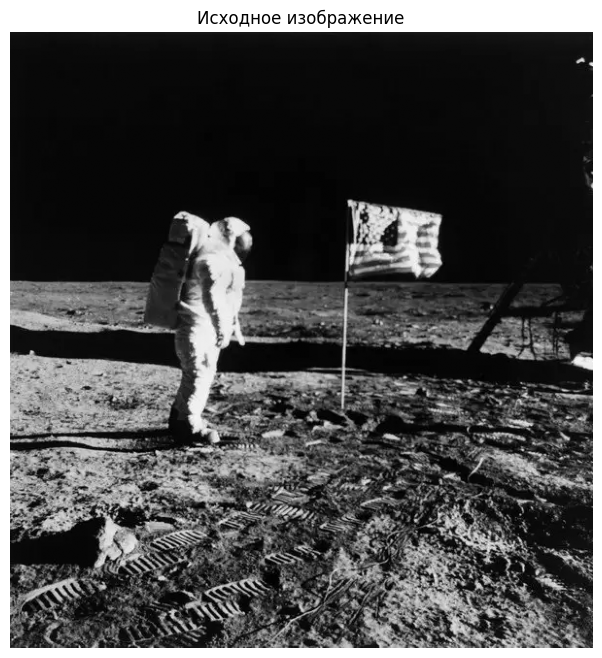

In [1]:
import numpy as np
import cv2 as cv
from matplotlib import pyplot as plt

# изображение в оттенках серого
img = cv.imread('cosmo.JPG', cv.IMREAD_GRAYSCALE)

if img is None:
    raise FileNotFoundError("Изображение cosmo.JPG не найдено")

# Размеры изображения
rows, cols = img.shape

print("Размер изображения:", img.shape)

# исходное изображение
plt.figure(figsize=(9, 8))
plt.imshow(img, cmap='gray')
plt.title('Исходное изображение')
plt.axis('off')
plt.show()

1 задание


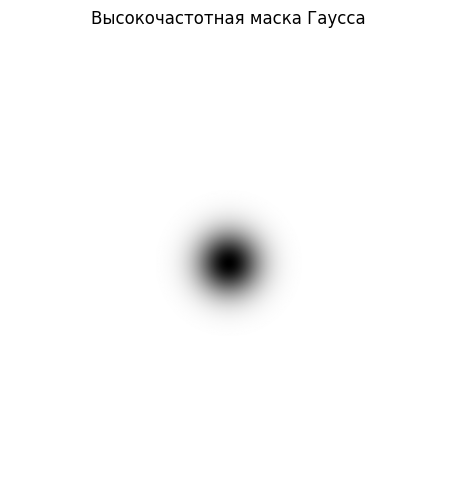

In [19]:
# прямое преобразование Фурье
dft = cv.dft(
    np.float32(img),
    flags=cv.DFT_COMPLEX_OUTPUT
)

# Переносим нулевую частоту в центр спектра
dft_shift = np.fft.fftshift(dft, axes=(0, 1))

# размеры изображения
rows, cols = img.shape

# Создаем координатную сетку
x, y = np.meshgrid(
    np.arange(0, cols, 1),
    np.arange(0, rows, 1)
)

#  параметр гауссова фильтра
sigma = 30

# гауссова функция
gauss = np.exp(
    -((x - (cols // 2))**2 + (y - (rows // 2))**2)
    / (2 * sigma**2)
)


mask_res = 1 - gauss


plt.figure(figsize=(8, 6))
plt.imshow(mask_res, cmap='gray')
plt.title('Высокочастотная маска Гаусса')
plt.axis('off')
plt.show()



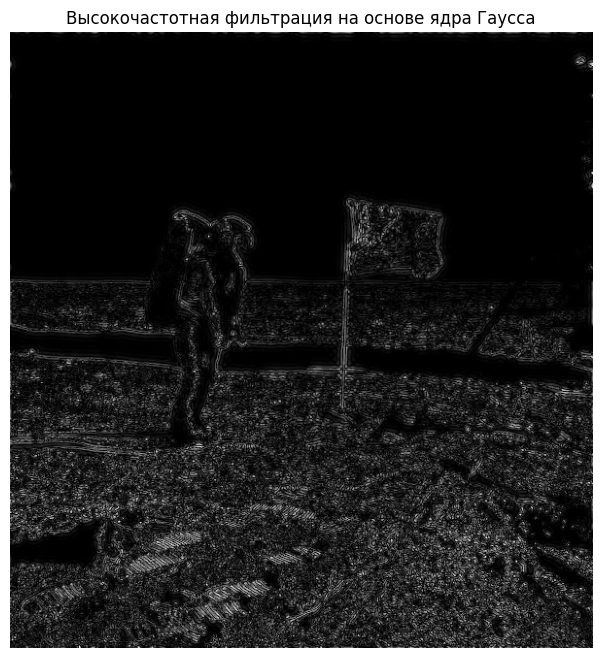

In [43]:
# маска спекрального изображения
dft_shift = dft_shift * mask_res[:, :, np.newaxis]

# обратное преобразование Фурье
img_idft = cv.idft(
    np.fft.ifftshift(dft_shift, axes=(0, 1)),
    flags=cv.DFT_SCALE
)

# амплитуда результата
img_idft = cv.magnitude(
    img_idft[:, :, 0],
    img_idft[:, :, 1]
)

# результат для отображения
img_idft = cv.normalize(
    img_idft,
    None,
    100,
    255,
    cv.NORM_MINMAX
).astype(np.uint8)


plt.figure(figsize=(10, 8))
plt.imshow(img_idft, cmap='gray')
plt.title('Высокочастотная фильтрация на основе ядра Гаусса')
plt.axis('off')
plt.show()

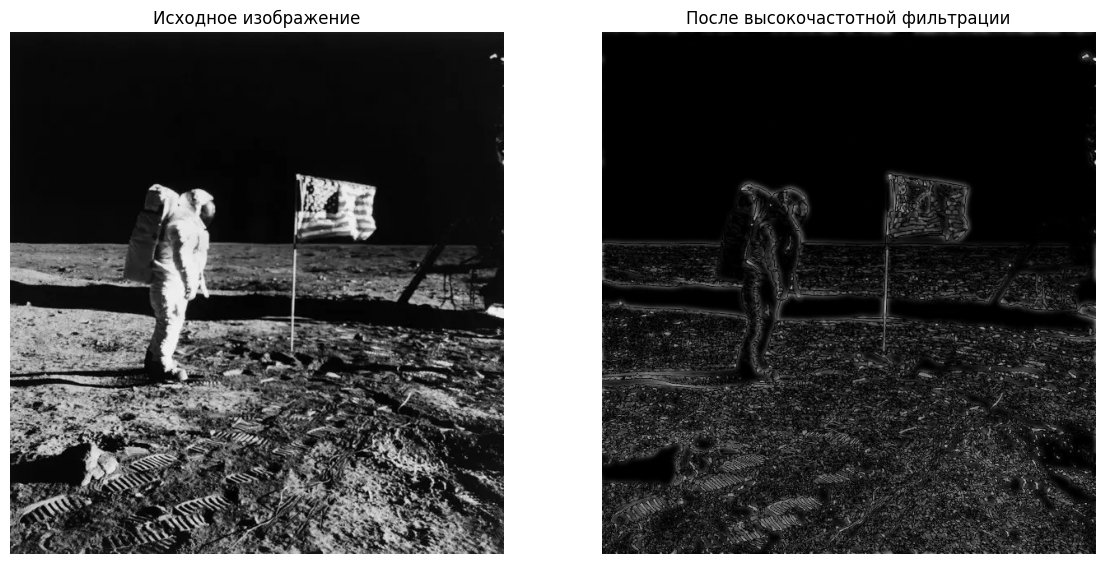

In [21]:

plt.figure(figsize=(14, 7))

# Исходное изображение
plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title('Исходное изображение')
plt.axis('off')

# Результат высокочастотной фильтрации
plt.subplot(1, 2, 2)
plt.imshow(img_idft, cmap='gray')
plt.title('После высокочастотной фильтрации')
plt.axis('off')

plt.show()

2 задание


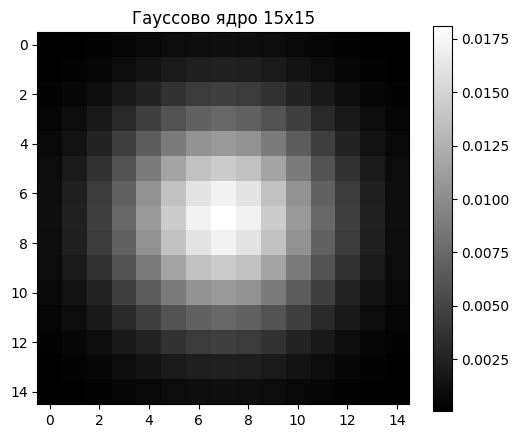

In [46]:
# одномерное гауссово ядро
kernel = cv.getGaussianKernel(15, 3)


# Преобразуем его в двумерное ядро
kernel = np.outer(kernel, kernel)

# гауссово ядро
plt.figure(figsize=(6, 5))
plt.imshow(kernel, cmap='gray')
plt.title('Гауссово ядро 15x15')
plt.colorbar()
plt.show()

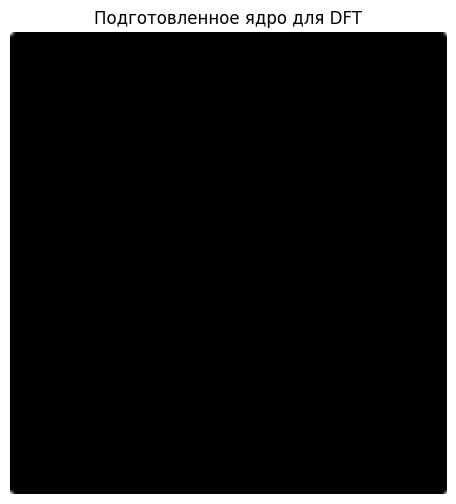

In [47]:
# Создаем массив размером с исходное изображение
kernel_pad = np.zeros_like(img, dtype=np.float32)

# размеры ядра
kh, kw = kernel.shape

# ядро в левом верхнем углу массива
kernel_pad[:kh, :kw] = kernel

# центр ядра в начало массива
kernel_pad = np.roll(kernel_pad, -(kh // 2), axis=0)
kernel_pad = np.roll(kernel_pad, -(kw // 2), axis=1)

plt.figure(figsize=(7, 6))
plt.imshow(kernel_pad, cmap='gray')
plt.title('Подготовленное ядро для DFT')
plt.axis('off')
plt.show()

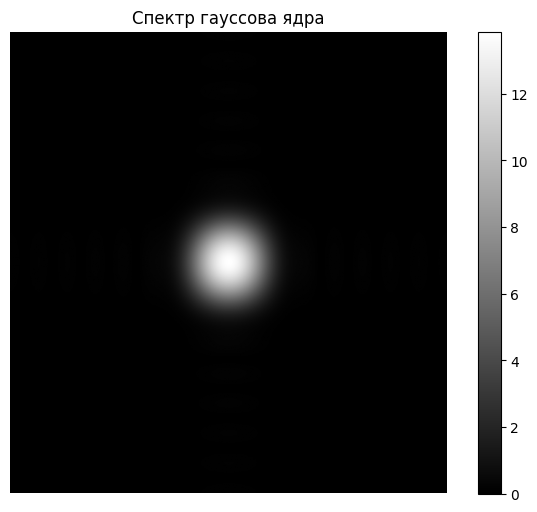

In [48]:
# преобразование Фурье изображения
dft_img = cv.dft(
    np.float32(img),
    flags=cv.DFT_COMPLEX_OUTPUT
)

# преобразование Фурье ядра
dft_kernel = cv.dft(
    kernel_pad,
    flags=cv.DFT_COMPLEX_OUTPUT
)

# нулевая частота в центре спектра ядра
dft_kernel_shift = np.fft.fftshift(
    dft_kernel,
    axes=(0, 1)
)

#  спектр ядра
kernel_spec = 20 * np.log(
    cv.magnitude(
        dft_kernel_shift[:, :, 0],
        dft_kernel_shift[:, :, 1]
    ) + 1
)


plt.figure(figsize=(8, 6))
plt.imshow(kernel_spec, cmap='gray')
plt.title('Спектр гауссова ядра')
plt.axis('off')
plt.colorbar()
plt.show()

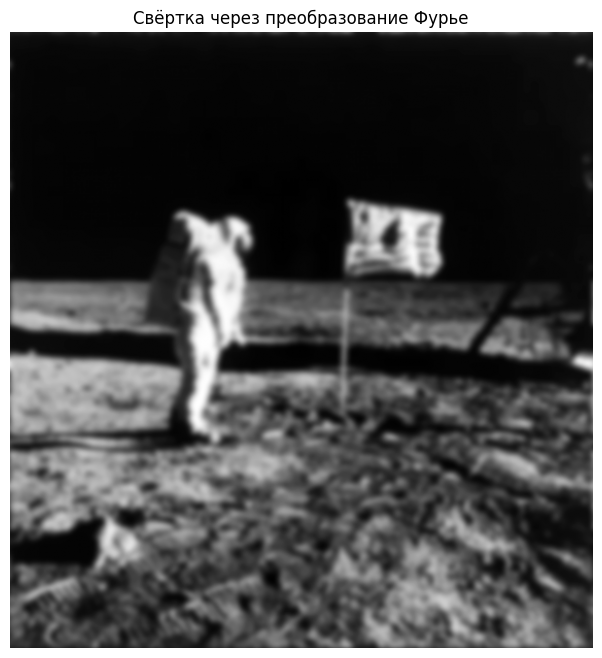

In [49]:
#спектрытры изображения * ядра
dft_conv = cv.mulSpectrums(
    dft_img,
    dft_kernel,
    0
)

# обратное преобразование Фурье
img_idft = cv.idft(
    dft_conv,
    flags=cv.DFT_SCALE
)

# Вычисляем амплитуду результата
img_idft = cv.magnitude(
    img_idft[:, :, 0],
    img_idft[:, :, 1]
)

# Приводим результат к диапазону 0-255
img_idft = np.clip(img_idft, 0, 255).astype(np.uint8)


plt.figure(figsize=(9, 8))
plt.imshow(img_idft, cmap='gray')
plt.title('Свёртка через преобразование Фурье')
plt.axis('off')
plt.show()

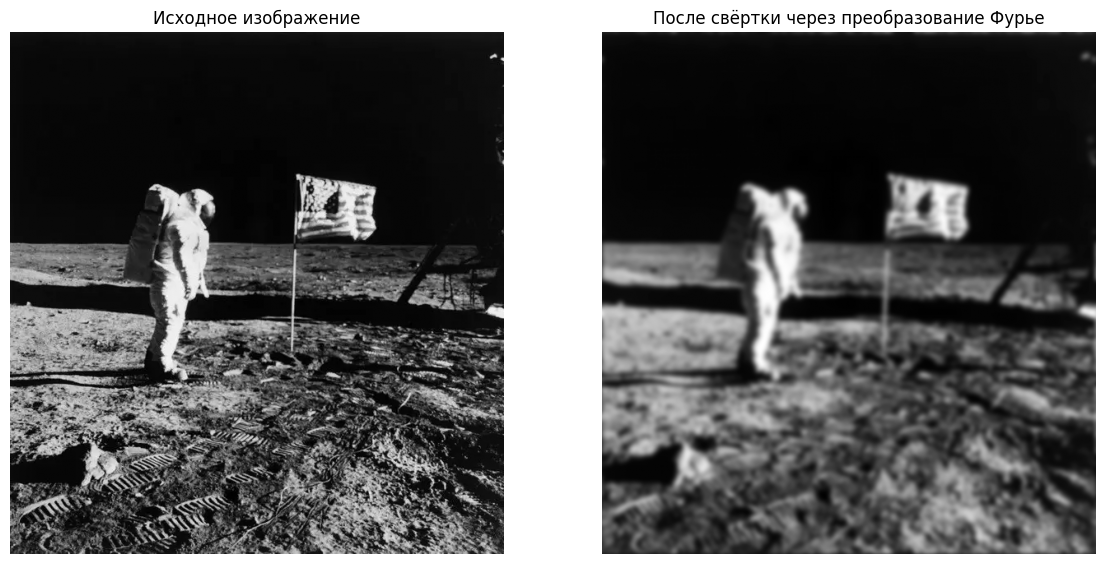

In [50]:
# исходное изображение и результат свёртки
plt.figure(figsize=(14, 7))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title('Исходное изображение')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img_idft, cmap='gray')
plt.title('После свёртки через преобразование Фурье')
plt.axis('off')

plt.show()

задание 3


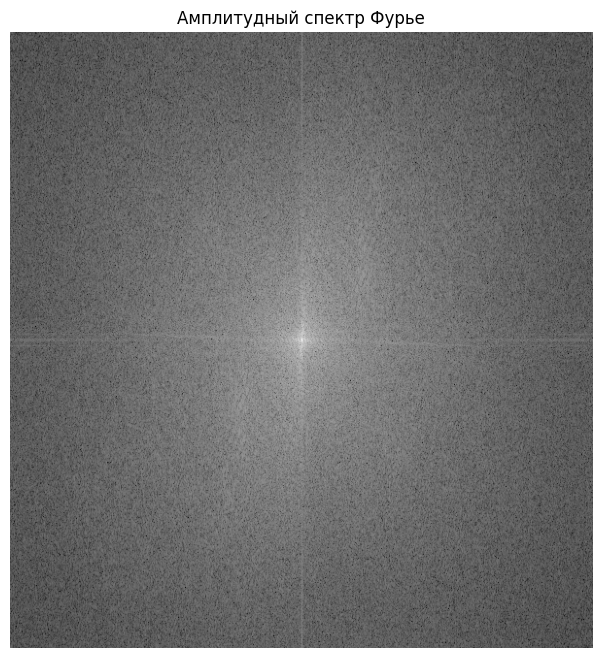

In [51]:
# функция поиска локальных максимумов
from skimage.feature import peak_local_max

# прямое преобразование Фурье
dft = cv.dft(
    np.float32(img),
    flags=cv.DFT_COMPLEX_OUTPUT
)

# Переносим нулевую частоту в центр
dft_shift = np.fft.fftshift(dft, axes=(0, 1))

# размеры изображения
rows, cols = img.shape

# амплитудный спектр
magnitude_spectrum = 20 * np.log(
    cv.magnitude(
        dft_shift[:, :, 0],
        dft_shift[:, :, 1]
    ) + 1
)

plt.figure(figsize=(10, 8))
plt.imshow(magnitude_spectrum, cmap='gray')
plt.title('Амплитудный спектр Фурье')
plt.axis('off')
plt.show()

Количество найденных максимумов: 651


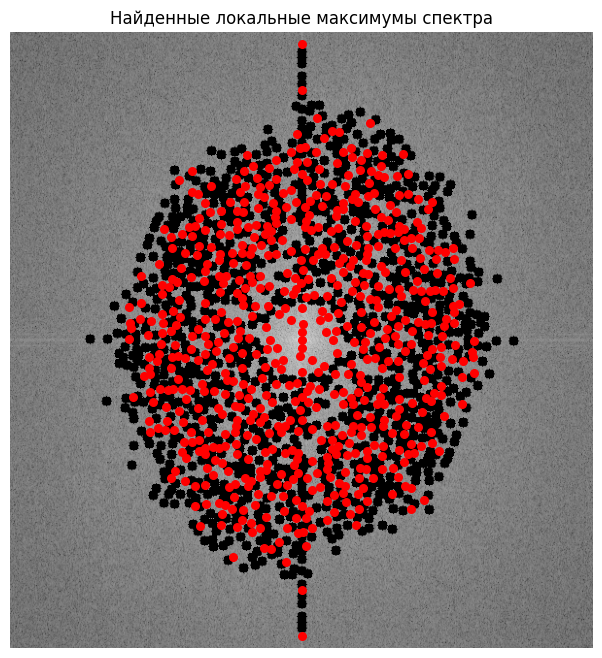

In [65]:
# яркие локальные максимумы спектра
local_max = peak_local_max(
    magnitude_spectrum,
    min_distance=5,
    threshold_abs=200
)


print("Количество найденных максимумов:", len(local_max))

plt.figure(figsize=(10, 8))
plt.imshow(magnitude_spectrum, cmap='gray')

for peak in local_max:
    y, x = peak
    plt.scatter(x, y, color='red', s=30)

plt.title('Найденные локальные максимумы спектра')
plt.axis('off')
plt.show()

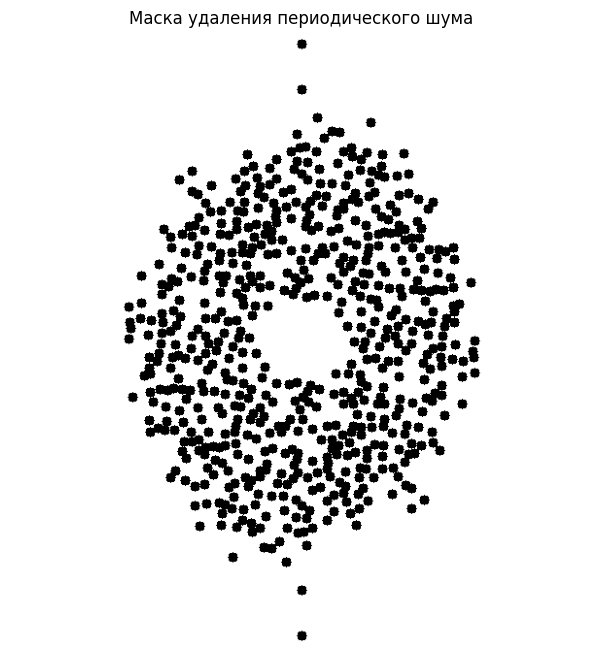

In [66]:
# Создаем маску, заполненную единицами
mask = np.ones((rows, cols), dtype=np.float32)

# Определяем центр спектра
center_y, center_x = rows // 2, cols // 2

#  найденные максимумы
for peak in local_max:

    y, x = peak

    # расстояние от центра спектра
    distance = np.sqrt(
        (x - center_x)**2 +
        (y - center_y)**2
    )


    if distance > 40:


        cv.circle(
            mask,
            (int(x), int(y)),
            5,
            0,
            -1
        )

plt.figure(figsize=(10, 8))
plt.imshow(mask, cmap='gray')
plt.title('Маска удаления периодического шума')
plt.axis('off')
plt.show()

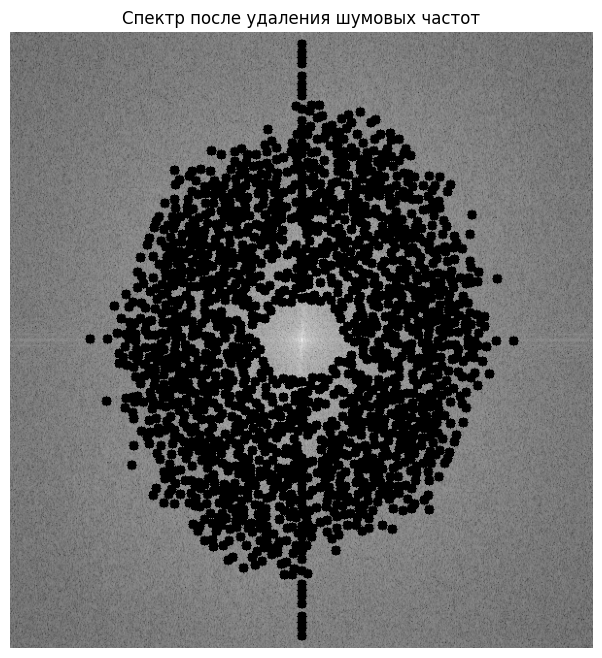

In [67]:
# Применяем маску к 2 составляющим спектра
dft_shift = dft_shift * mask[:, :, np.newaxis]

magnitude_spectrum = 20 * np.log(
    cv.magnitude(
        dft_shift[:, :, 0],
        dft_shift[:, :, 1]
    ) + 1
)


plt.figure(figsize=(10, 8))
plt.imshow(magnitude_spectrum, cmap='gray')
plt.title('Спектр после удаления шумовых частот')
plt.axis('off')
plt.show()

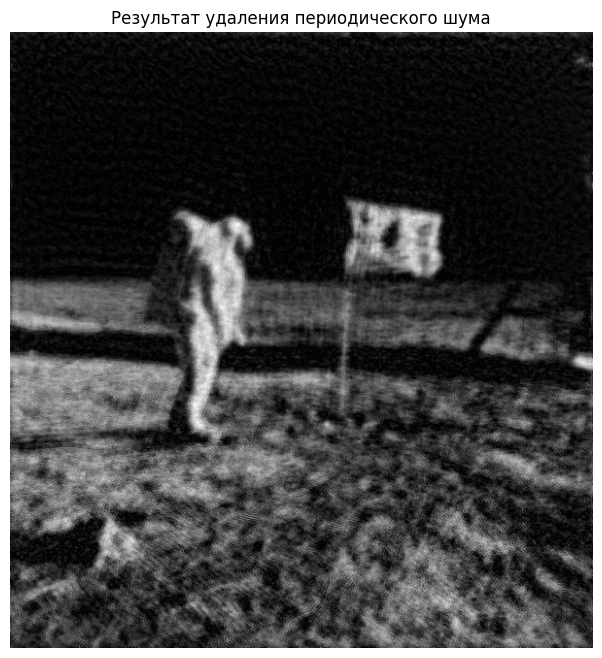

In [68]:
# Возвращаем нулевую частоту на прежнее место
dft_ishift = np.fft.ifftshift(
    dft_shift,
    axes=(0, 1)
)

# обратное преобразование Фурье
img_idft = cv.idft(
    dft_ishift,
    flags=cv.DFT_SCALE
)

# амплитуда результата
img_idft = cv.magnitude(
    img_idft[:, :, 0],
    img_idft[:, :, 1]
)


img_result = cv.normalize(
    img_idft,
    None,
    0,
    255,
    cv.NORM_MINMAX
).astype(np.uint8)


plt.figure(figsize=(9, 8))
plt.imshow(img_result, cmap='gray')
plt.title('Результат удаления периодического шума')
plt.axis('off')
plt.show()

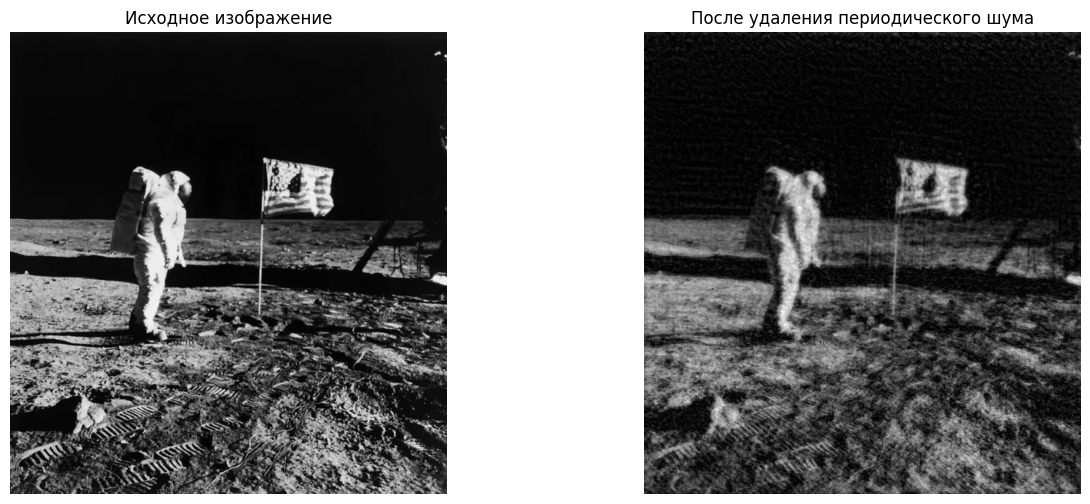

In [63]:
plt.figure(figsize=(15, 6))

# Исходное изображение
plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title('Исходное изображение')
plt.axis('off')

# Изображение после фильтрации
plt.subplot(1, 2, 2)
plt.imshow(img_result, cmap='gray')
plt.title('После удаления периодического шума')
plt.axis('off')

plt.show()